In [152]:
import numpy as np
import time
import datetime
import os
import struct
import numba
import matplotlib as mpl
import matplotlib.pyplot as plt
import pickle 
import RemoteCorrelationAnalysis as ca
from scipy.stats import poisson
from tqdm.notebook import tqdm

In [12]:
fpath = r'Q:\CorrelationFPGA'
fname = r'23-09-16--11-56-17_0_0_0_0.b'


In [115]:
chunksize= 2**11
n_chunks = 0

with open(fpath+os.sep+fname, "rb") as inputfile:
    try:
        while True:
            data_dwords = np.frombuffer(inputfile.read(4*chunksize),
                                        dtype=np.uint32,
                                        count=chunksize)
            n_chunks += 1
    except ValueError:
        pass


In [116]:

inputfile = open(fpath+os.sep+fname, "rb")
data_dwords = np.frombuffer(inputfile.read(4*chunksize),
                            dtype=np.uint32, count=chunksize)
special, channels, wrapped_times = ca.extract_records_hydra(data_dwords)
channels, timestamps = ca.unwrap_time_hydra(special, channels, wrapped_times)
inputfile.close()

Text(0.5, 0, 'Photon arrivaltimes us')

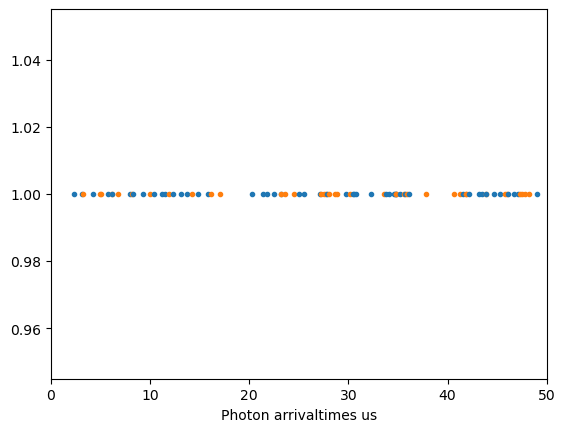

In [117]:
plt.figure()
for i in range(len(timestamps)):
    plt.plot(timestamps[i]*1e-6, 1,'.',color='C'+str(channels[i]))
plt.xlim(0,50)
plt.xlabel('Photon arrivaltimes us')

In [118]:
dt0 = []
dt1 = []
laststamp0 = 0
laststamp1 = 0
for i in range(len(timestamps)):
    if channels[i] == 0:
        dt0.append(timestamps[i]-laststamp0)
        laststamp0 = timestamps[i]
    else:
        dt1.append(timestamps[i]-laststamp1)
        laststamp1 = timestamps[i]
dt0 = np.array(dt0)
dt1 = np.array(dt1)

Text(0, 0.5, 'Timedifferences us')

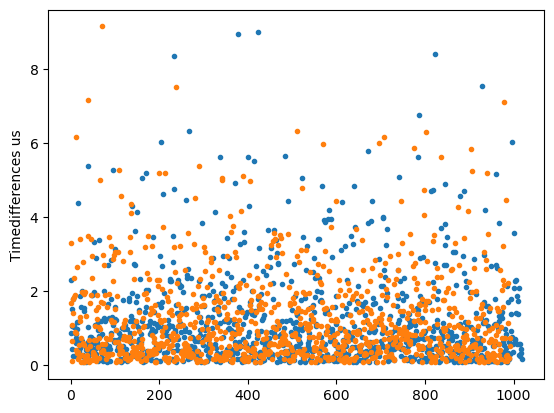

In [119]:
plt.figure()
plt.plot((dt0*1e-6),'.')
plt.plot((dt1*1e-6),'.')
plt.ylabel('Timedifferences us')

Text(0.5, 0, 'Ctr MHz')

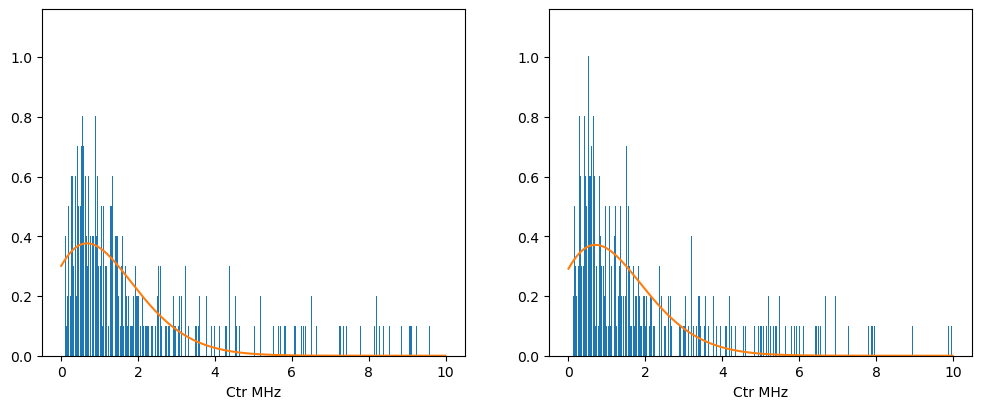

In [144]:
binwidth = 0.01
bins = np.arange(0, 10, binwidth)
hist0,_ = np.histogram(1/(dt0*1e-6), bins)
hist1,_ = np.histogram(1/(dt1*1e-6), bins)



fig = plt.figure(figsize=(12,4.5))
ax = fig.add_subplot(1,2,1)

ax.bar(bins[:-1], hist0/np.sum(hist0)/binwidth, width=0.8*binwidth)
poisson_dist = poisson.pmf(bins, np.mean(dt0*1e-6))
ax.plot(bins, poisson_dist, color='C1')
ax.set_xlabel(r'Ctr MHz')

ax = fig.add_subplot(1,2,2)

ax.bar(bins[:-1], hist1/np.sum(hist0)/binwidth, width=0.8*binwidth)
poisson_dist = poisson.pmf(bins, np.mean(dt1*1e-6))
ax.plot(bins, poisson_dist, color='C1')
# ax.set_xlim(0,0.5)

# ax.set_xlabel(r'$\Delta \tau$ $\mu s$')
ax.set_xlabel(r'Ctr MHz')

In [130]:
print(np.sum(hist0))
rho = hist0/np.sum(hist0*binwidth)
print(np.sum(rho*binwidth))

1019
1.0


In [212]:
binwidth = 0.01
bins = np.arange(0, 10, binwidth)

hist0 = np.zeros((len(bins)-1))
hist1 = np.zeros((len(bins)-1))
hist01 = np.zeros((len(bins)-1))
inputfile = open(fpath+os.sep+fname, "rb")
for j in tqdm(range(10000)):
# for j in range(30):
    data_dwords = np.frombuffer(inputfile.read(4*chunksize),
                                    dtype=np.uint32, count=chunksize)
    special, channels, wrapped_times = ca.extract_records_hydra(data_dwords)
    channels, timestamps = ca.unwrap_time_hydra(special, channels, wrapped_times)
    curr_dt0 = []
    curr_dt1 = []
    laststamp0 = 0
    laststamp1 = 0
    for i in range(len(timestamps)):
        if channels[i] == 0:
            curr_dt0.append(timestamps[i]-laststamp0)
            laststamp0 = timestamps[i]
        else:
            curr_dt1.append(timestamps[i]-laststamp1)
            laststamp1 = timestamps[i]
    curr_dt0 = np.array(curr_dt0)
    curr_dt1 = np.array(curr_dt1)
    currhist, _ = np.histogram(curr_dt0*1e-6, bins)
    hist0 += currhist
    currhist, _ = np.histogram(curr_dt1*1e-6, bins)
    hist1 += currhist
    
#     ca.fast_correlate(timestamps, channels, hist01, binwidth, np.min(bins), np.max(bins))
inputfile.close()

  0%|          | 0/10000 [00:00<?, ?it/s]

0.9999878220253174


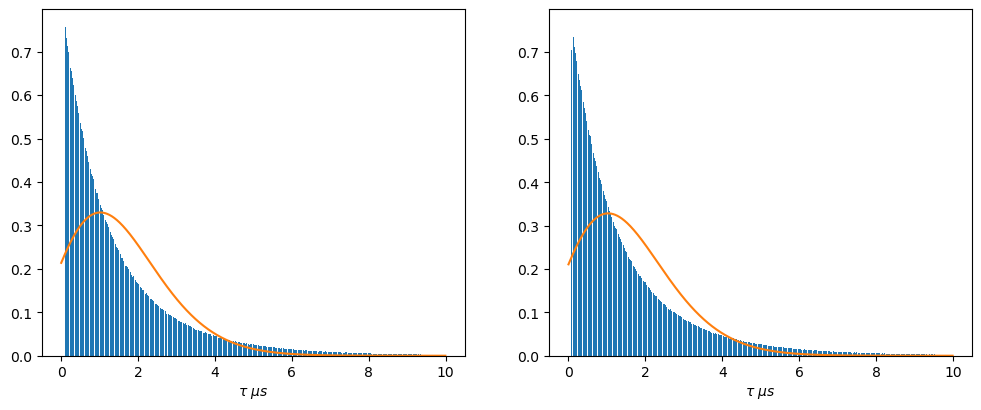

In [218]:

fig = plt.figure(figsize=(12,4.5))
ax = fig.add_subplot(1,2,1)

ax.bar(bins[:-1], hist0/np.sum(hist0)/binwidth, width=0.8*binwidth)

mean0 = np.sum(hist0*bins[:-1])/np.sum(hist0)
std0 = np.sqrt(np.sum( (bins[:-1] - mean0)**2 * hist0) / (np.sum(hist0)-1))
poisson_dist = poisson.pmf(bins, mean0)
ax.plot(bins, poisson_dist, color='C1')

ax.set_xlabel(r'$\tau$ $\mu s$')
ax = fig.add_subplot(1,2,2)

ax.bar(bins[:-1], hist1/np.sum(hist1)/binwidth, width=0.8*binwidth)
mean1 = np.sum(hist1*bins[:-1])/np.sum(hist1)
std1 = np.sqrt(np.sum( (bins[:-1] - mean1)**2 * hist1) / (np.sum(hist1)-1))
poisson_dist = poisson.pmf(bins, mean1)
ax.plot(bins, poisson_dist, color='C1')
# ax.set_xlim(0,1)

ax.set_xlabel(r'$\tau$ $\mu s$')
print(np.trapz(hist1/np.sum(hist1)/binwidth)*binwidth)

In [214]:
np.trapz(hist1/np.sum(hist1)/binwidth)*binwidth

0.9999878220253174

In [197]:
tint = 1e7
binwidth = 1
bins = np.arange(0, 30, binwidth)
hist0 = np.zeros(len(bins)-1)
hist1 = np.zeros(len(bins)-1)

inputfile = open(fpath+os.sep+fname, "rb")

for j in tqdm(range(5000)):
# for j in range(3):
    data_dwords = np.frombuffer(inputfile.read(4*chunksize),
                                    dtype=np.uint32, count=chunksize)
    special, channels, wrapped_times = ca.extract_records_hydra(data_dwords)
    channels, timestamps = ca.unwrap_time_hydra(special, channels, wrapped_times)
    cts0 = []
    cts1 = []
    currcts0 = 0
    currcts1 = 0
    t0 = 0
    t1 = 0
    for i in range(len(timestamps)):
        if channels[i] == 0:
            if timestamps[i]-t0 > tint:
                t0 = timestamps[i]
                cts0.append(currcts0)
                currcts0 = 0
            else:
                currcts0 += 1
        else:
            if timestamps[i]-t1 > tint:
                t1 = timestamps[i]
                cts1.append(currcts1)
                currcts1 = 1
            else:
                currcts1 += 1
    currhist, _ = np.histogram(cts0, bins)
    hist0 += currhist
    currhist, _ = np.histogram(cts1, bins)
    hist1 += currhist
inputfile.close()

  0%|          | 0/5000 [00:00<?, ?it/s]

3.1571436029916318 2.5089568583424593
3.1041179640436427 2.6671047272912443


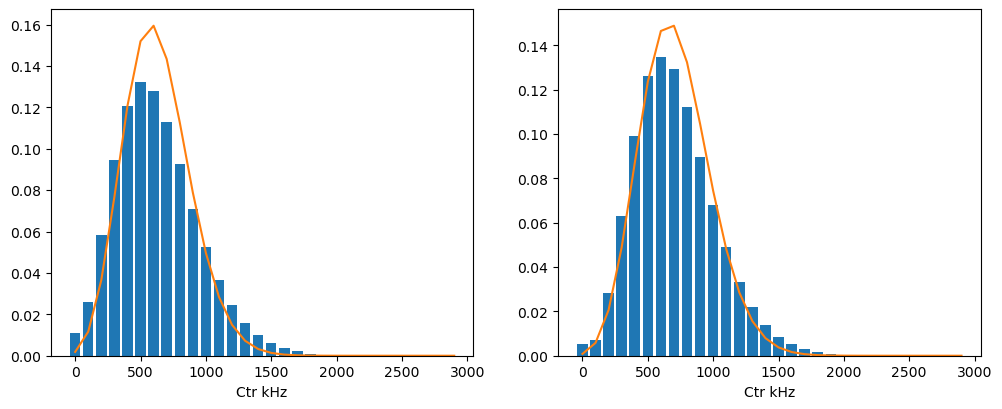

In [199]:
fig = plt.figure(figsize=(12,4.5))
ax = fig.add_subplot(1,2,1)

ax.bar(bins[:-1]*1e2, hist0/np.sum(hist0)/binwidth, width=0.8*binwidth*1e2)
mean0 = np.sum(hist0*bins[:-1])/np.sum(hist0)
std0 = np.sqrt(np.sum( (bins[:-1] - mean0)**2 * hist0) / (np.sum(hist0)-1))
poisson_dist = poisson.pmf(bins, mean0)
ax.plot(bins*1e2, poisson_dist, color='C1')

ax.set_xlabel(r'Ctr kHz')
ax = fig.add_subplot(1,2,2)

ax.bar(bins[:-1]*1e2, hist1/np.sum(hist1)/binwidth, width=0.8*binwidth*1e2)
mean1 = np.sum(hist1*bins[:-1])/np.sum(hist1)
std1 = np.sqrt(np.sum((bins[:-1]-mean1)**2*hist1)/(np.sum(hist1)-1))
poisson_dist = poisson.pmf(bins, mean1)
ax.plot(bins*1e2, poisson_dist, color='C1')
# ax.set_xlim(0,1)

ax.set_xlabel(r'Ctr kHz')

print(std0, np.sqrt(mean0))
print(std1, np.sqrt(mean1))

6.298446174399595